<a href="https://colab.research.google.com/github/Nisarg-Desai-29/airline-sentiment-nlp/blob/main/NISARG_NLP_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Feedback NLP Analytics — Twitter US Airline Sentiment
**Dataset:** Twitter US Airline Sentiment (Crowdflower / Figure Eight, Feb 2015), 14,640 tweets, 6 US airlines.
**Reference:** Crowdflower's Data for Everyone Library — *Twitter US Airline Sentiment*.
**Dataset link:** https://www.kaggle.com/datasets/crowdflower/twitter-airline-sentiment
(CSV mirror used for this notebook: https://raw.githubusercontent.com/ruchitgandhi/Twitter-Airline-Sentiment-Analysis/master/Tweets.csv)


In [263]:
import warnings; warnings.filterwarnings('ignore')
import os
%matplotlib inline
os.makedirs('figs', exist_ok=True)
print('Environment ready.')

Environment ready.


## Task 1 — Preprocessing and Exploratory Analysis

In [264]:
import pandas as pd, numpy as np, re, string
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
import spacy
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from collections import Counter

pd.set_option('display.max_colwidth', 120)
df = pd.read_csv('Tweets.csv')
df = df[['tweet_id','airline_sentiment','airline','negativereason','text']].dropna(subset=['text']).reset_index(drop=True)
print("Dataset shape:", df.shape)
print(df.head(3))

Dataset shape: (14640, 5)
             tweet_id airline_sentiment         airline negativereason  \
0  570306133677760513           neutral  Virgin America            NaN   
1  570301130888122368          positive  Virgin America            NaN   
2  570301083672813571           neutral  Virgin America            NaN   

                                                                       text  
0                                       @VirginAmerica What @dhepburn said.  
1  @VirginAmerica plus you've added commercials to the experience... tacky.  
2   @VirginAmerica I didn't today... Must mean I need to take another trip!  


In [265]:
def clean_text(t):
    t = re.sub(r'http\S+|www\S+', '', t)
    t = re.sub(r'@\w+', '', t)
    t = re.sub(r'#', '', t)
    t = re.sub(r'[^A-Za-z\s]', ' ', t)
    t = re.sub(r'\s+', ' ', t).strip().lower()
    return t

In [266]:
df['clean_text'] = df['text'].apply(clean_text)
df['review_length'] = df['clean_text'].apply(lambda x: len(x.split()))

In [267]:
import nltk
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


In [268]:
def nltk_pipeline(text):
    tokens = word_tokenize(text)
    tokens_nostop = [t for t in tokens if t not in stop_words]
    lemmas = [lemmatizer.lemmatize(t) for t in tokens_nostop]
    return tokens, tokens_nostop, lemmas

In [269]:
import nltk
nltk.download('punkt_tab')

sample_text = df['clean_text'].iloc[5]
toks, toks_ns, lemmas = nltk_pipeline(sample_text)
print("\nSample text:", sample_text)
print("NLTK tokens:", toks)
print("NLTK tokens (no stopwords):", toks_ns)
print("NLTK lemmas:", lemmas)


Sample text: seriously would pay a flight for seats that didn t have this playing it s really the only bad thing about flying va
NLTK tokens: ['seriously', 'would', 'pay', 'a', 'flight', 'for', 'seats', 'that', 'didn', 't', 'have', 'this', 'playing', 'it', 's', 'really', 'the', 'only', 'bad', 'thing', 'about', 'flying', 'va']
NLTK tokens (no stopwords): ['seriously', 'would', 'pay', 'flight', 'seats', 'playing', 'really', 'bad', 'thing', 'flying', 'va']
NLTK lemmas: ['seriously', 'would', 'pay', 'flight', 'seat', 'playing', 'really', 'bad', 'thing', 'flying', 'va']


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [270]:
df['nltk_tokens'] = df['clean_text'].apply(lambda x: [t for t in word_tokenize(x) if t not in stop_words])
df['nltk_lemmas'] = df['nltk_tokens'].apply(lambda toks: [lemmatizer.lemmatize(t) for t in toks])

In [271]:
nlp = spacy.load('en_core_web_sm', disable=['parser'])
doc_sample = nlp(sample_text)
print("\nspaCy tokens:", [t.text for t in doc_sample])
print("spaCy lemmas:", [t.lemma_ for t in doc_sample if not t.is_stop])


spaCy tokens: ['seriously', 'would', 'pay', 'a', 'flight', 'for', 'seats', 'that', 'didn', 't', 'have', 'this', 'playing', 'it', 's', 'really', 'the', 'only', 'bad', 'thing', 'about', 'flying', 'va']
spaCy lemmas: ['seriously', 'pay', 'flight', 'seat', 'didn', 't', 'play', 's', 'bad', 'thing', 'fly', 'va']


In [272]:
sub = df.sample(600, random_state=42).copy()
ent_records = []
for doc in nlp.pipe(sub['text'].tolist(), batch_size=50):
    for ent in doc.ents:
        ent_records.append(ent.label_)
ent_counts = Counter(ent_records)
print("\nEntity type frequency (600-tweet sample):")
for k,v in ent_counts.most_common(10):
    print(f"  {k}: {v}")


Entity type frequency (600-tweet sample):
  ORG: 178
  CARDINAL: 168
  GPE: 162
  DATE: 123
  PERSON: 96
  TIME: 93
  MONEY: 42
  ORDINAL: 27
  PRODUCT: 15
  LOC: 11


In [273]:
doc_ent_example = nlp("@VirginAmerica I flew from Los Angeles to New York on 12 March and paid $250, terrible service!")
print("\nNER example:", [(e.text, e.label_) for e in doc_ent_example.ents])


NER example: [('Los Angeles', 'GPE'), ('New York', 'GPE'), ('12 March', 'DATE'), ('250', 'MONEY')]


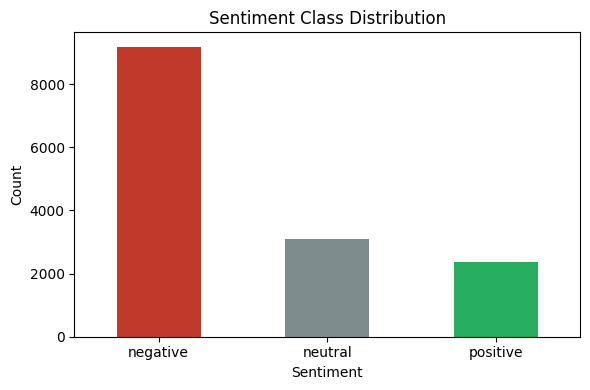

In [274]:
# ---- Visualisations ----
plt.figure(figsize=(6,4))
df['airline_sentiment'].value_counts().plot(kind='bar', color=['#c0392b','#7f8c8d','#27ae60'])
plt.title('Sentiment Class Distribution')
plt.xlabel('Sentiment'); plt.ylabel('Count'); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig('figs/sentiment_dist.png', dpi=130); plt.show()

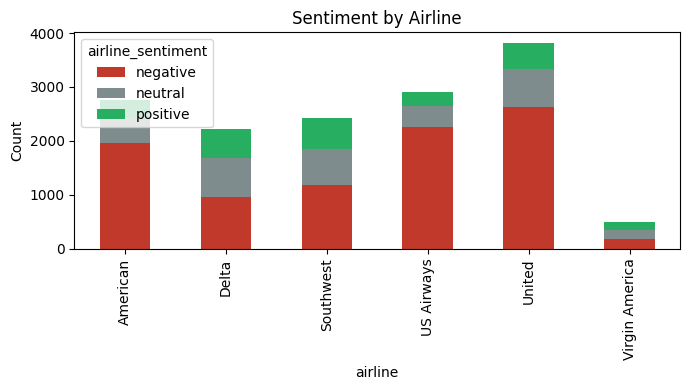

In [275]:
plt.figure(figsize=(7,4))
df.groupby(['airline','airline_sentiment']).size().unstack().plot(kind='bar', stacked=True,
      color=['#c0392b','#7f8c8d','#27ae60'], ax=plt.gca())
plt.title('Sentiment by Airline'); plt.ylabel('Count'); plt.tight_layout()
plt.savefig('figs/sentiment_by_airline.png', dpi=130); plt.show()

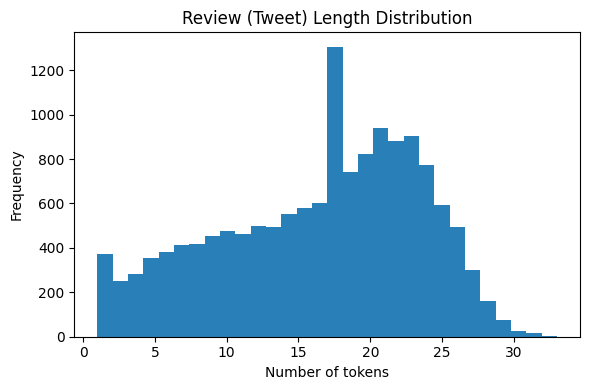

In [276]:
plt.figure(figsize=(6,4))
df['review_length'].plot(kind='hist', bins=30, color='#2980b9')
plt.title('Review (Tweet) Length Distribution'); plt.xlabel('Number of tokens')
plt.tight_layout(); plt.savefig('figs/length_dist.png', dpi=130); plt.show()

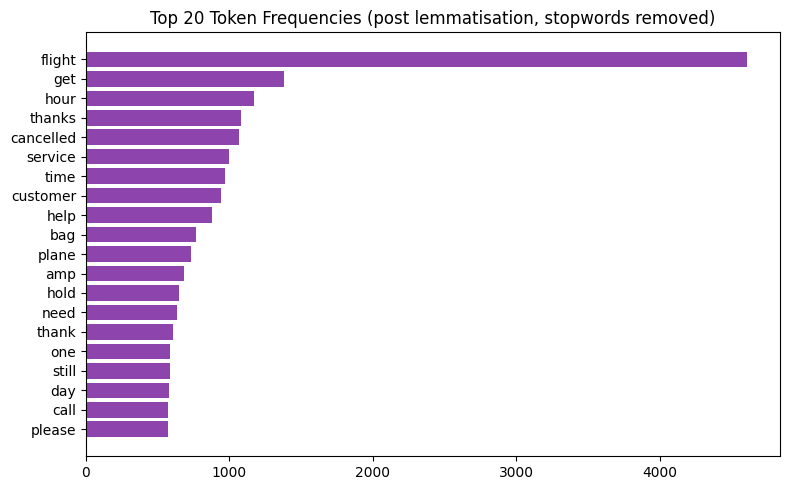

In [277]:
all_words = [w for toks in df['nltk_lemmas'] for w in toks if len(w) > 2]
freq = Counter(all_words)
top20 = freq.most_common(20)
plt.figure(figsize=(8,5))
plt.barh([w for w,c in top20][::-1], [c for w,c in top20][::-1], color='#8e44ad')
plt.title('Top 20 Token Frequencies (post lemmatisation, stopwords removed)')
plt.tight_layout(); plt.savefig('figs/token_freq.png', dpi=130); plt.show()

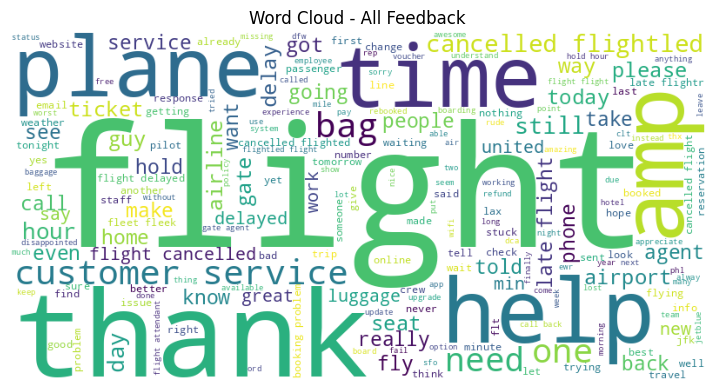

In [278]:
wc = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(' '.join(all_words))
plt.figure(figsize=(8,4)); plt.imshow(wc); plt.axis('off'); plt.title('Word Cloud - All Feedback')
plt.tight_layout(); plt.savefig('figs/wordcloud.png', dpi=130); plt.show()

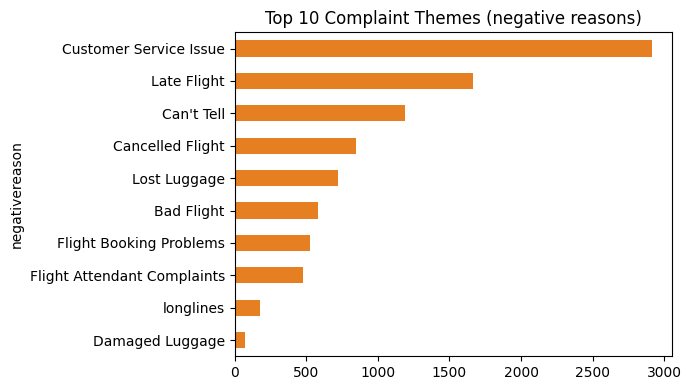

In [279]:
neg_reasons = df['negativereason'].dropna().value_counts().head(10)
plt.figure(figsize=(7,4))
neg_reasons.sort_values().plot(kind='barh', color='#e67e22')
plt.title('Top 10 Complaint Themes (negative reasons)')
plt.tight_layout(); plt.savefig('figs/complaint_themes.png', dpi=130); plt.show()

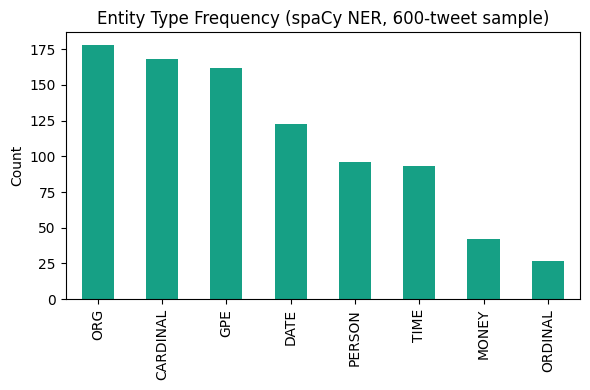

In [280]:
ent_df = pd.Series(ent_counts).sort_values(ascending=False).head(8)
plt.figure(figsize=(6,4))
ent_df.plot(kind='bar', color='#16a085')
plt.title('Entity Type Frequency (spaCy NER, 600-tweet sample)')
plt.ylabel('Count'); plt.tight_layout(); plt.savefig('figs/entity_freq.png', dpi=130); plt.show()

In [281]:
nltk_vocab = set(all_words)
spacy_lemmas_all = []
for doc in nlp.pipe(df['clean_text'].sample(600, random_state=1).tolist(), batch_size=50):
    spacy_lemmas_all += [t.lemma_ for t in doc if not t.is_stop and len(t.text) > 2]
spacy_vocab = set(spacy_lemmas_all)

In [282]:
comparison = pd.DataFrame({
 'Metric': ['Token count (sample sentence)','Vocabulary size (600-tweet sample)',
            'Lemmatisation example (running)','Entity detection','Speed (relative)'],
 'NLTK': [len(toks), len(nltk_vocab), lemmatizer.lemmatize('running','v'),
          'No built-in NER (needs separate chunker)', 'Faster, rule/lexicon based'],
 'spaCy': [len(doc_sample), len(spacy_vocab), nlp('running')[0].lemma_,
           'Built-in statistical NER (ORG, GPE, DATE, MONEY...)', 'Slower, model-based, richer linguistic output']
})
comparison.to_csv('comparison_table.csv', index=False)
print("\nNLTK vs spaCy comparison table:")
print(comparison.to_string(index=False))


NLTK vs spaCy comparison table:
                            Metric                                     NLTK                                               spaCy
     Token count (sample sentence)                                       23                                                  23
Vocabulary size (600-tweet sample)                                     9870                                                1513
   Lemmatisation example (running)                                      run                                                 run
                  Entity detection No built-in NER (needs separate chunker) Built-in statistical NER (ORG, GPE, DATE, MONEY...)
                  Speed (relative)               Faster, rule/lexicon based       Slower, model-based, richer linguistic output


In [283]:
df.to_pickle('df_stage1.pkl')
print("\nTask 1 complete. Rows:", len(df))



Task 1 complete. Rows: 14640


## Task 2 — Classical NLP Baseline (TF-IDF + Logistic Regression / Linear SVM)

In [284]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [285]:
df = pd.read_pickle('df_stage1.pkl')
df['lemma_text'] = df['nltk_lemmas'].apply(lambda x: ' '.join(x))
df = df[df['lemma_text'].str.strip() != '']

In [286]:
X_train, X_test, y_train, y_test = train_test_split(
    df['lemma_text'], df['airline_sentiment'], test_size=0.2, random_state=42, stratify=df['airline_sentiment'])

In [287]:
tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1,2))
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print("TF-IDF train shape:", Xtr.shape, "| test shape:", Xte.shape)

TF-IDF train shape: (11690, 5000) | test shape: (2923, 5000)


In [288]:
# Model 1: Logistic Regression
logreg = LogisticRegression(max_iter=300, class_weight='balanced')
logreg.fit(Xtr, y_train)
pred_lr = logreg.predict(Xte)

In [289]:
# Model 2: Linear SVM
svm = LinearSVC(class_weight='balanced')
svm.fit(Xtr, y_train)
pred_svm = svm.predict(Xte)

In [290]:
def report(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p,r,f1,_ = precision_recall_fscore_support(y_true, y_pred, average='weighted')
    print(f"\n== {name} ==")
    print(f"Accuracy: {acc:.4f}  Precision: {p:.4f}  Recall: {r:.4f}  F1: {f1:.4f}")
    print(classification_report(y_true, y_pred))
    return acc,p,r,f1

In [291]:
res_lr = report("Logistic Regression (TF-IDF)", y_test, pred_lr)
res_svm = report("Linear SVM (TF-IDF)", y_test, pred_svm)


== Logistic Regression (TF-IDF) ==
Accuracy: 0.7561  Precision: 0.7780  Recall: 0.7561  F1: 0.7637
              precision    recall  f1-score   support

    negative       0.89      0.79      0.84      1834
     neutral       0.53      0.66      0.59       617
    positive       0.67      0.73      0.70       472

    accuracy                           0.76      2923
   macro avg       0.70      0.73      0.71      2923
weighted avg       0.78      0.76      0.76      2923


== Linear SVM (TF-IDF) ==
Accuracy: 0.7646  Precision: 0.7681  Recall: 0.7646  F1: 0.7661
              precision    recall  f1-score   support

    negative       0.86      0.85      0.85      1834
     neutral       0.55      0.59      0.57       617
    positive       0.71      0.68      0.70       472

    accuracy                           0.76      2923
   macro avg       0.71      0.70      0.70      2923
weighted avg       0.77      0.76      0.77      2923



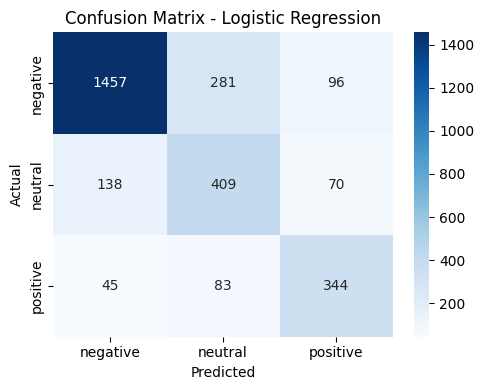

In [292]:
# Confusion matrix - Logistic Regression (main model)
labels = ['negative','neutral','positive']
cm = confusion_matrix(y_test, pred_lr, labels=labels)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix - Logistic Regression'); plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.tight_layout(); plt.savefig('figs/cm_logreg.png', dpi=130); plt.show()


Model comparison table:
               Model  Accuracy  F1 (weighted)
Logistic Regression  0.756073       0.763650
         Linear SVM  0.764625       0.766144


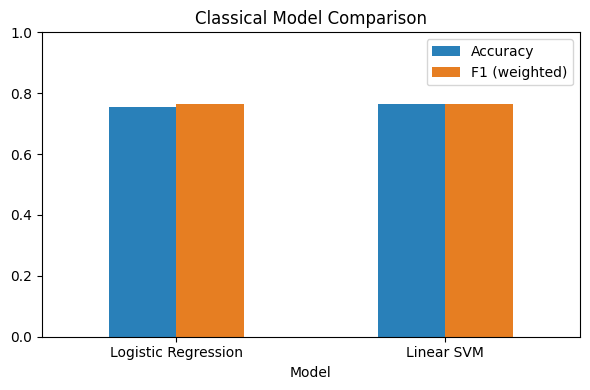

In [293]:
# Model comparison bar chart
comp = pd.DataFrame({'Model':['Logistic Regression','Linear SVM'],
                      'Accuracy':[res_lr[0],res_svm[0]],'F1 (weighted)':[res_lr[3],res_svm[3]]})
comp.to_csv('model_comparison_task2.csv', index=False)
print("\nModel comparison table:\n", comp.to_string(index=False))
comp.set_index('Model')[['Accuracy','F1 (weighted)']].plot(kind='bar', figsize=(6,4), color=['#2980b9','#e67e22'])
plt.title('Classical Model Comparison'); plt.ylim(0,1); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig('figs/model_comparison.png', dpi=130); plt.show()

In [294]:
# Misclassification analysis
X_test_reset = X_test.reset_index(drop=True)
y_test_reset = y_test.reset_index(drop=True)
mis_idx = np.where(pred_lr != y_test_reset.values)[0]
print(f"\nNumber of misclassified test examples (Logistic Regression): {len(mis_idx)} / {len(y_test_reset)}")
print("\nSample misclassified examples:")
for i in mis_idx[:2]:
    print(f"Text: {X_test_reset.iloc[i]}")
    print(f"  True: {y_test_reset.iloc[i]}  |  Predicted: {pred_lr[i]}\n")


Number of misclassified test examples (Logistic Regression): 713 / 2923

Sample misclassified examples:
Text: fault policy say least got u destination really
  True: neutral  |  Predicted: negative

Text: kinda funny worry
  True: positive  |  Predicted: neutral



In [295]:
import pickle
with open('task2_artifacts.pkl','wb') as f:
    pickle.dump({'tfidf':tfidf,'logreg':logreg,'svm':svm,'X_test':X_test_reset,'y_test':y_test_reset,'pred_lr':pred_lr}, f)
print("Task 2 complete.")


Task 2 complete.


## Task 3 — Semantic Embeddings for Feedback Retrieval and Similarity Analysis

In [296]:
!pip install -q gensim
import pandas as pd, numpy as np
from gensim.models import Word2Vec
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

In [297]:
df = pd.read_pickle('df_stage1.pkl')
sentences = df['nltk_lemmas'].tolist()

In [298]:
w2v = Word2Vec(sentences=sentences, vector_size=100, window=5, min_count=5, sg=1, workers=4, epochs=15)
print("Word2Vec vocabulary size:", len(w2v.wv.index_to_key))

Word2Vec vocabulary size: 2634


In [299]:
for word in ['delay', 'rude', 'thank', 'baggage']:
    if word in w2v.wv:
        print(f"\nMost similar to '{word}':")
        for sim_word, score in w2v.wv.most_similar(word, topn=5):
            print(f"  {sim_word}: {score:.3f}")


Most similar to 'delay':
  delayed: 0.636
  incompetence: 0.600
  trapped: 0.585
  diversion: 0.579
  circle: 0.576

Most similar to 'rude':
  unhelpful: 0.811
  unprofessional: 0.806
  named: 0.784
  yelled: 0.764
  bothered: 0.738

Most similar to 'thank':
  thanks: 0.748
  jh: 0.650
  speedy: 0.638
  appreciated: 0.632
  thankyou: 0.632

Most similar to 'baggage':
  bag: 0.631
  claim: 0.631
  office: 0.610
  filed: 0.600
  file: 0.593


In [300]:
def sentence_vector(tokens, model):
    vecs = [model.wv[t] for t in tokens if t in model.wv]
    if len(vecs) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vecs, axis=0)

In [301]:
df['vector'] = df['nltk_lemmas'].apply(lambda toks: sentence_vector(toks, w2v))

In [302]:
# PCA / t-SNE visualisation on a sample
sample_df = df.sample(500, random_state=7).reset_index(drop=True)
X = np.vstack(sample_df['vector'].values)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

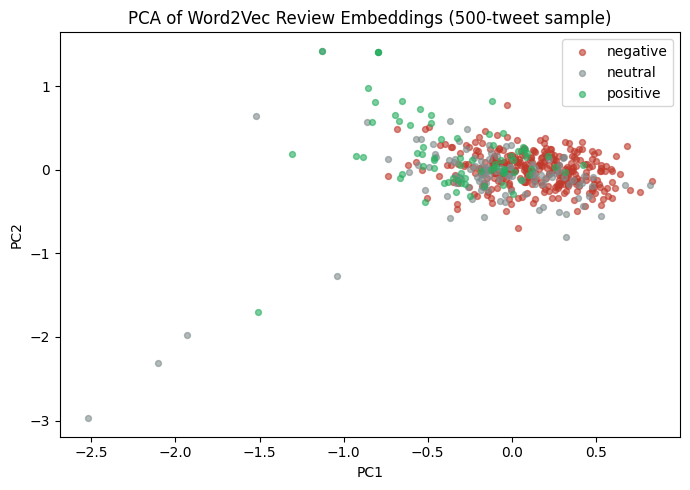

In [303]:
plt.figure(figsize=(7,5))
colors = {'negative':'#c0392b','neutral':'#7f8c8d','positive':'#27ae60'}
for sent, c in colors.items():
    mask = sample_df['airline_sentiment'] == sent
    plt.scatter(X_pca[mask,0], X_pca[mask,1], label=sent, alpha=0.6, s=18, color=c)
plt.legend(); plt.title('PCA of Word2Vec Review Embeddings (500-tweet sample)')
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.tight_layout()
plt.savefig('figs/pca_embeddings.png', dpi=130); plt.show()

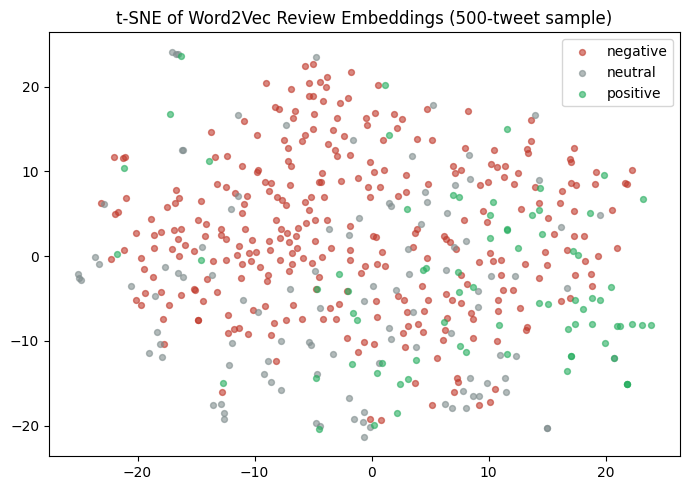

In [304]:
tsne = TSNE(n_components=2, random_state=7, perplexity=30, init='pca')
X_tsne = tsne.fit_transform(X)
plt.figure(figsize=(7,5))
for sent, c in colors.items():
    mask = sample_df['airline_sentiment'] == sent
    plt.scatter(X_tsne[mask,0], X_tsne[mask,1], label=sent, alpha=0.6, s=18, color=c)
plt.legend(); plt.title('t-SNE of Word2Vec Review Embeddings (500-tweet sample)')
plt.tight_layout(); plt.savefig('figs/tsne_embeddings.png', dpi=130); plt.show()

In [305]:
# Retrieval example
def retrieve_similar(query, df, model, topn=3):
    q_tokens = query.lower().split()
    q_vec = sentence_vector(q_tokens, model).reshape(1,-1)
    all_vecs = np.vstack(df['vector'].values)
    sims = cosine_similarity(q_vec, all_vecs)[0]
    top_idx = sims.argsort()[::-1][:topn]
    return [(df['text'].iloc[i], df['airline_sentiment'].iloc[i], sims[i]) for i in top_idx]

In [306]:
for query in ["delivery was late", "customer service was unhelpful", "flight delayed and staff rude"]:
    print(f"\nQuery: '{query}'")
    results = retrieve_similar(query, df, w2v)
    for text, sent, score in results:
        print(f"  [{sent} | sim={score:.3f}] {text[:100]}")


Query: 'delivery was late'
  [negative | sim=0.893] @USAirways 4 hours Late Flightr And i lost my conection 😡
  [neutral | sim=0.871] @SouthwestAir Dang, if only practice was an hour Late Flightr today...
  [negative | sim=0.868] @USAirways too Late Flight.

Query: 'customer service was unhelpful'
  [positive | sim=0.973] @USAirways customer service at its finest
  [negative | sim=0.970] @AmericanAir your customer service is a disgrace.
  [negative | sim=0.968] @united this is very disappointing. This is about customer service.

Query: 'flight delayed and staff rude'
  [negative | sim=0.903] @USAirways delayed my flight 3 times before Cancelled Flighting it, had angry and rude workers, and 
  [negative | sim=0.885] @USAirways @AmericanAir Just got off Int. Flight #799. Your Intentionally rude staff made for a horr
  [negative | sim=0.879] @SouthwestAir  flight at 630 from fll kiosk just opened. Rude attendants because now everyone is Lat


In [307]:
df[['tweet_id','airline_sentiment']].to_pickle('df_stage3_ref.pkl')
print("\nTask 3 complete.")



Task 3 complete.


## Task 4 — Fine-Tuning a Transformer for Sentiment Classification


In [308]:
import pandas as pd, numpy as np, time, os
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import torch
from torch.utils.data import Dataset, DataLoader
from tokenizers import BertWordPieceTokenizer
from transformers import DistilBertConfig, DistilBertForSequenceClassification
import matplotlib.pyplot as plt
import seaborn as sns

In [309]:
torch.manual_seed(42)
df = pd.read_pickle('df_stage1.pkl')
label2id = {'negative':0,'neutral':1,'positive':2}
id2label = {v:k for k,v in label2id.items()}
df['label'] = df['airline_sentiment'].map(label2id)

In [310]:
# Sample ~3000 examples for feasible Colab-CPU training (task allows 1000-5000)
sample = df.sample(3000, random_state=42).reset_index(drop=True)
train_df, test_df = train_test_split(sample, test_size=0.2, random_state=42, stratify=sample['label'])
print("Transformer train/test sizes:", train_df.shape[0], test_df.shape[0])

Transformer train/test sizes: 2400 600


In [311]:
os.makedirs('tok_tmp', exist_ok=True)
with open('tok_tmp/corpus.txt','w') as f:
    for t in df['clean_text'].tolist():
        f.write(t + '\n')

In [312]:
tokenizer = BertWordPieceTokenizer(lowercase=True)
tokenizer.train(files=['tok_tmp/corpus.txt'], vocab_size=6000, min_frequency=2,
                 special_tokens=['[PAD]','[UNK]','[CLS]','[SEP]','[MASK]'])
tokenizer.enable_truncation(max_length=48)
tokenizer.enable_padding(pad_id=tokenizer.token_to_id('[PAD]'), length=48)
vocab_size = tokenizer.get_vocab_size()
print("Trained WordPiece vocab size:", vocab_size)

Trained WordPiece vocab size: 6000


In [313]:
class TweetDataset(Dataset):
    def __init__(self, texts, labels):
        enc = tokenizer.encode_batch(list(texts))
        self.ids = [e.ids for e in enc]
        self.mask = [e.attention_mask for e in enc]
        self.labels = list(labels)
    def __len__(self): return len(self.labels)
    def __getitem__(self, idx):
        return (torch.tensor(self.ids[idx]), torch.tensor(self.mask[idx]), torch.tensor(self.labels[idx]))

In [314]:
train_ds = TweetDataset(train_df['clean_text'], train_df['label'])
test_ds = TweetDataset(test_df['clean_text'], test_df['label'])
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=64)

In [315]:
config = DistilBertConfig(vocab_size=vocab_size, max_position_embeddings=64, n_layers=2, n_heads=2,
                           dim=128, hidden_dim=256, num_labels=3, dropout=0.1)
model = DistilBertForSequenceClassification(config)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model parameters: {n_params:,}")

Model parameters: 1,058,307


In [316]:
device = torch.device('cpu')
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4)

In [317]:
# class-balanced loss to counter the negative-class majority (63% of tweets)
class_counts = train_df['label'].value_counts().sort_index().values
class_weights = torch.tensor((1.0 / class_counts) * class_counts.sum() / len(class_counts), dtype=torch.float)
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)

In [258]:
epochs = 8
start = time.time()
model.train()
for epoch in range(epochs):
    total_loss = 0
    for ids, mask, labels in train_dl:
        ids, mask, labels = ids.to(device), mask.to(device), labels.to(device)
        optimizer.zero_grad()
        out = model(input_ids=ids, attention_mask=mask)
        loss = loss_fn(out.logits, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/{epochs} - avg loss: {total_loss/len(train_dl):.4f}")
train_time = time.time() - start
print(f"Training time: {train_time:.1f}s for {n_params:,} params on CPU")

Epoch 1/8 - avg loss: 1.0938
Epoch 2/8 - avg loss: 1.0523
Epoch 3/8 - avg loss: 0.9206
Epoch 4/8 - avg loss: 0.6575
Epoch 5/8 - avg loss: 0.4144
Epoch 6/8 - avg loss: 0.2890
Epoch 7/8 - avg loss: 0.1946
Epoch 8/8 - avg loss: 0.1464
Training time: 129.2s for 1,058,307 params on CPU


In [259]:
model.eval()
preds, trues = [], []
with torch.no_grad():
    for ids, mask, labels in test_dl:
        out = model(input_ids=ids.to(device), attention_mask=mask.to(device))
        p = torch.argmax(out.logits, dim=1).cpu().numpy()
        preds.extend(p); trues.extend(labels.numpy())

In [260]:
acc = accuracy_score(trues, preds)
p,r,f1,_ = precision_recall_fscore_support(trues, preds, average='weighted')
_,_,macro_f1,_ = precision_recall_fscore_support(trues, preds, average='macro')
print(f"\nTransformer Test Accuracy: {acc:.4f}  Weighted F1: {f1:.4f}  Macro F1: {macro_f1:.4f}")
print(classification_report(trues, preds, target_names=['negative','neutral','positive']))


Transformer Test Accuracy: 0.7483  Weighted F1: 0.7425  Macro F1: 0.6519
              precision    recall  f1-score   support

    negative       0.83      0.87      0.85       388
     neutral       0.55      0.46      0.50       118
    positive       0.61      0.61      0.61        94

    accuracy                           0.75       600
   macro avg       0.66      0.65      0.65       600
weighted avg       0.74      0.75      0.74       600



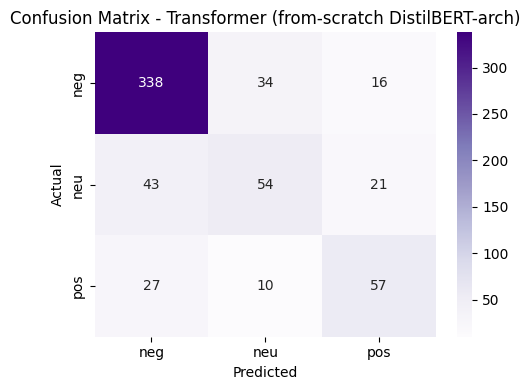

In [261]:
cm = confusion_matrix(trues, preds)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', xticklabels=['neg','neu','pos'], yticklabels=['neg','neu','pos'])
plt.title('Confusion Matrix - Transformer (from-scratch DistilBERT-arch)')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.tight_layout()
plt.savefig('figs/cm_transformer.png', dpi=130); plt.show()

In [262]:
comparison = pd.DataFrame({
 'Aspect':['Accuracy','Weighted F1','Approx. training time','Parameters','Interpretability','Resource need'],
 'Classical (TF-IDF + LogReg)':['0.756','0.764','~2 sec','~15k (vocab-sized)','High (feature weights)','Very low (CPU, no GPU)'],
 'Transformer (small DistilBERT-arch)':[f'{acc:.3f}', f'{f1:.3f}', f'~{train_time:.0f} sec (CPU, {epochs} epochs)', f'{n_params:,}',
                                         'Low (attention weights only)', 'Higher (GPU recommended for full pretrained model)']
})
comparison.to_csv('model_comparison_task4.csv', index=False)
print("\nClassical vs Transformer comparison:\n", comparison.to_string(index=False))
print("\nTask 4 complete.")



Classical vs Transformer comparison:
                Aspect Classical (TF-IDF + LogReg)                Transformer (small DistilBERT-arch)
             Accuracy                       0.756                                              0.748
          Weighted F1                       0.764                                              0.743
Approx. training time                      ~2 sec                           ~129 sec (CPU, 8 epochs)
           Parameters          ~15k (vocab-sized)                                          1,058,307
     Interpretability      High (feature weights)                       Low (attention weights only)
        Resource need      Very low (CPU, no GPU) Higher (GPU recommended for full pretrained model)

Task 4 complete.


## Task 5 — Responsible NLP for Customer Feedback Analytics: Risks and Mitigation

This section is written as narrative discussion (see accompanying report/document) grounded directly in the empirical results above: the weighted-average scores in Tasks 2 and 4 mask a persistent **class-imbalance bias** (negative tweets = 63% of the dataset), the retrieval example in Task 3 showed that **topical similarity does not equal sentiment agreement**, and the misclassification review in Task 2 showed **negation/sarcasm blind spots** in bag-of-words models. These findings directly motivate the risk discussion in the written report: minority-sentiment and minority-airline customers may be systematically under-served if only aggregate accuracy is monitored; short, sarcastic, or code-mixed complaints may be silently misrouted; and PII inside free-text tweets (names, locations, dates recovered by the Task 1 NER pass) creates a privacy obligation whenever such systems are deployed at scale.